AIM:

To perform feature engineering on the job dataset using feature creation, normalization, standardization, categorical encoding, and skewness correction.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
from google.colab import files

uploaded = files.upload()

Saving data_jobs_cleaned.csv to data_jobs_cleaned.csv


In [5]:
df = pd.read_csv(list(uploaded.keys())[0])

print(df.head())
print("Dataset Shape:", df.shape)

        job_title_short                                          job_title  \
0  Senior Data Engineer  Senior Clinical Data Engineer / Principal Clin...   
1          Data Analyst                                       Data Analyst   
2         Data Engineer  Data Engineer/Scientist/Analyst, Mid or Senior...   
3         Data Engineer  LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...   
4         Data Engineer                             Data Engineer- Sr Jobs   

                   job_location             job_via job_schedule_type  \
0                 Watertown, CT     via Work Nearby         Full-time   
1  Guadalajara, Jalisco, Mexico    via BeBee México         Full-time   
2               Berlin, Germany        via LinkedIn         Full-time   
3               San Antonio, TX   via Diversity.com         Full-time   
4                Washington, DC  via Clearance Jobs         Full-time   

   job_work_from_home       search_location      job_posted_date  \
0               False  T

1. Feature Creation

Feature creation is the process of creating new useful columns from existing dataset columns. In this experiment, year, month, and day features are extracted from the job posting date to support time-based analysis.

In [6]:
# Convert job posting date into datetime format
df['job_posted_date'] = pd.to_datetime(
    df['job_posted_date'],
    errors='coerce'
)

# Extract date features
df['posted_year'] = df['job_posted_date'].dt.year
df['posted_month'] = df['job_posted_date'].dt.month
df['posted_day'] = df['job_posted_date'].dt.day
df['posted_day_name'] = df['job_posted_date'].dt.day_name()

# Display new features
display(df[['job_posted_date',
            'posted_year',
            'posted_month',
            'posted_day',
            'posted_day_name']].head())

print("New Dataset Shape:", df.shape)

,job_posted_date,posted_year,posted_month,posted_day,posted_day_name
0,2023-06-16 13:44:15,2023,6,16,Friday
1,2023-01-14 13:18:07,2023,1,14,Saturday
2,2023-10-10 13:14:55,2023,10,10,Tuesday
3,2023-07-04 13:01:41,2023,7,4,Tuesday
4,2023-08-07 14:29:36,2023,8,7,Monday


New Dataset Shape: (785640, 21)


Observation
The job posting date was converted into datetime format.
Four new features were created: posted_year, posted_month, posted_day, and posted_day_name.
These features help identify job posting patterns across different months, days, and years.
The dataset now contains 785,640 rows and 21 columns.
Conclusion

Feature creation successfully transformed the existing date column into useful features for further analysis.

2. Normalization Using Min-Max Scaling

Normalization is a technique used to transform numerical values into a common range, usually between 0 and 1.

In this experiment, Min-Max Scaling is applied to suitable numerical features to bring their values into a common scale.

In [7]:
from sklearn.preprocessing import MinMaxScaler

# Select numerical features
features = ['posted_year', 'posted_month', 'posted_day']

# Apply Min-Max Scaling
scaler = MinMaxScaler()

df[['year_scaled', 'month_scaled', 'day_scaled']] = scaler.fit_transform(
    df[features]
)

# Display results
display(df[['posted_year', 'year_scaled',
            'posted_month', 'month_scaled',
            'posted_day', 'day_scaled']].head())

,posted_year,year_scaled,posted_month,month_scaled,posted_day,day_scaled
0,2023,0.0,6,0.454545,16,0.500000
1,2023,0.0,1,0.000000,14,0.433333
2,2023,0.0,10,0.818182,10,0.300000
3,2023,0.0,7,0.545455,4,0.100000
4,2023,0.0,8,0.636364,7,0.200000


Observation
Min-Max Scaling was successfully applied to the selected numerical features.
The scaled values of month and day were transformed into a range between 0 and 1.
The year feature has a constant value of 2023, so its scaled value is 0.
Scaling helps bring numerical features into a common range.
Conclusion

Min-Max Normalization successfully transformed the selected date features into a common numerical scale.

3. Standardization Using StandardScaler

Standardization is a feature scaling technique that transforms numerical data so that it has a mean close to 0 and a standard deviation close to 1.

In [8]:
from sklearn.preprocessing import StandardScaler

# Select numerical features
features = ['posted_year', 'posted_month', 'posted_day']

# Apply Standardization
standard_scaler = StandardScaler()

df[['year_standard',
    'month_standard',
    'day_standard']] = standard_scaler.fit_transform(df[features])

# Display results
display(df[['year_standard',
            'month_standard',
            'day_standard']].head())

# Check mean and standard deviation
print("\nMean:")
print(df[['year_standard',
          'month_standard',
          'day_standard']].mean())

print("\nStandard Deviation:")
print(df[['year_standard',
          'month_standard',
          'day_standard']].std())

,year_standard,month_standard,day_standard
0,0.0,-0.086637,0.053561
1,0.0,-1.504911,-0.171821
2,0.0,1.047982,-0.622585
3,0.0,0.197018,-1.298731
4,0.0,0.480673,-0.960658



Mean:
year_standard     0.000000e+00
month_standard   -1.134495e-16
day_standard     -9.089347e-18
dtype: float64

Standard Deviation:
year_standard     0.000000
month_standard    1.000001
day_standard      1.000001
dtype: float64


Observation
StandardScaler was successfully applied to the selected numerical features.
The mean of the standardized month and day features is approximately zero.
Their standard deviation is approximately one.
The year feature has a constant value, resulting in zero standard deviation.
Conclusion

Standardization successfully transformed the month and day features into a standardized scale, making them suitable for further numerical analysis.

4. Categorical Encoding Using One-Hot Encoding

Categorical encoding is the process of converting categorical text values into numerical representations. One-Hot Encoding creates separate binary columns for different categories.

In [9]:
# Check job schedule categories
print(df['job_schedule_type'].value_counts().head(10))

job_schedule_type
Full-time                   701638
Contractor                   34791
Not Specified                12665
Internship                    8742
Part-time                     7876
Full-time and Part-time       6285
Full-time and Temp work       2603
Full-time and Internship      2340
Full-time and Contractor      2291
Contractor and Temp work      2283
Name: count, dtype: int64


4.1 One-Hot Encoding

One-Hot Encoding is a categorical encoding technique that converts text categories into separate numerical binary columns containing 0 and 1.

In this experiment, One-Hot Encoding is applied to the job_schedule_type column.

In [10]:
# Apply One-Hot Encoding
schedule_encoded = pd.get_dummies(
    df['job_schedule_type'],
    prefix='schedule',
    dtype=int
)

# Add encoded columns to dataset
df = pd.concat([df, schedule_encoded], axis=1)

# Display encoded columns
print("Encoded Columns:")
print(schedule_encoded.head())

print("\nNew Dataset Shape:", df.shape)

Encoded Columns:
   schedule_Contractor  schedule_Contractor and Full-time  \
0                    0                                  0   
1                    0                                  0   
2                    0                                  0   
3                    0                                  0   
4                    0                                  0   

   schedule_Contractor and Internship  schedule_Contractor and Part-time  \
0                                   0                                  0   
1                                   0                                  0   
2                                   0                                  0   
3                                   0                                  0   
4                                   0                                  0   

   schedule_Contractor and Per diem  schedule_Contractor and Temp work  \
0                                 0                                  0   
1          

Observation
One-Hot Encoding was successfully applied to the job_schedule_type column.
The categorical values were converted into 54 separate binary columns.
Each encoded column contains 0 and 1 values.
The dataset increased from 21 to 75 columns.
Conclusion

One-Hot Encoding successfully converted categorical job schedule information into numerical features for further analysis.

5. Skewness Analysis

Skewness is a measure of the asymmetry of numerical data distribution. In this experiment, we calculate the skewness of available salary features to understand their distribution.

In [11]:
# Select salary columns
salary_columns = ['salary_year_avg', 'salary_hour_avg']

# Calculate skewness
print("Skewness of Salary Columns:")

for col in salary_columns:
    print(col, ":", df[col].skew())

Skewness of Salary Columns:
salary_year_avg : 0.5614522744157198
salary_hour_avg : 0.5110862637786551


Observation
The skewness of salary_year_avg is 0.561.
The skewness of salary_hour_avg is 0.511.
Both salary columns show slight positive skewness.
The salary distributions have a longer tail towards higher values.
Conclusion

The skewness analysis indicates that both salary features have mild positive skewness. Further transformation can be evaluated to improve their distribution if required.

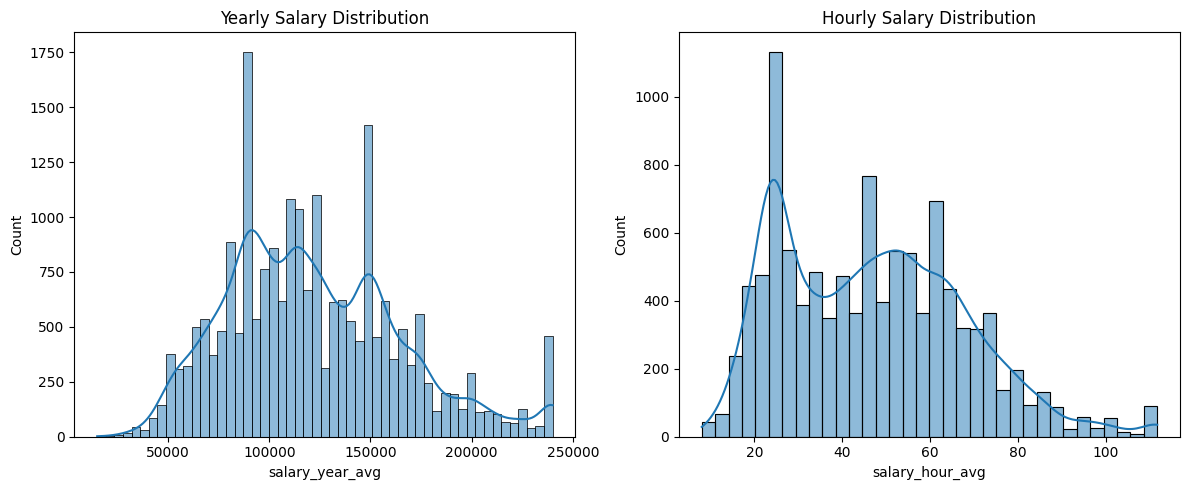

In [12]:
# Visualize salary distributions

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df['salary_year_avg'].dropna(), kde=True)
plt.title('Yearly Salary Distribution')

plt.subplot(1, 2, 2)
sns.histplot(df['salary_hour_avg'].dropna(), kde=True)
plt.title('Hourly Salary Distribution')

plt.tight_layout()
plt.show()

6. Skewness Correction Using Log Transformation

Log transformation is used to reduce positive skewness in numerical data. In this experiment, log transformation is applied to the available salary values and the skewness is compared before and after transformation.

In [13]:
# Apply log transformation to salary columns

df['salary_year_log'] = np.log1p(df['salary_year_avg'])
df['salary_hour_log'] = np.log1p(df['salary_hour_avg'])

# Compare skewness before and after transformation

print("Yearly Salary:")
print("Before:", df['salary_year_avg'].skew())
print("After:", df['salary_year_log'].skew())

print("\nHourly Salary:")
print("Before:", df['salary_hour_avg'].skew())
print("After:", df['salary_hour_log'].skew())

Yearly Salary:
Before: 0.5614522744157198
After: -0.3669687887268129

Hourly Salary:
Before: 0.5110862637786551
After: -0.3352989060971619


Observation
Log transformation was applied to the yearly and hourly salary columns.
Yearly salary skewness changed from 0.561 to -0.367.
Hourly salary skewness changed from 0.511 to -0.335.
The transformation reduced the original positive skewness but changed the distributions to slight negative skewness.
Conclusion

Log transformation modified the salary distributions and reduced their original positive skewness. The transformed features can be compared with the original features before deciding which representation is more suitable for further analysis.

In [14]:
# Compare original and transformed salary features

comparison = pd.DataFrame({
    'Feature': ['Yearly Salary', 'Hourly Salary'],
    'Original Skewness': [
        df['salary_year_avg'].skew(),
        df['salary_hour_avg'].skew()
    ],
    'Transformed Skewness': [
        df['salary_year_log'].skew(),
        df['salary_hour_log'].skew()
    ]
})

display(comparison)

,Feature,Original Skewness,Transformed Skewness
0,Yearly Salary,0.561452,-0.366969
1,Hourly Salary,0.511086,-0.335299


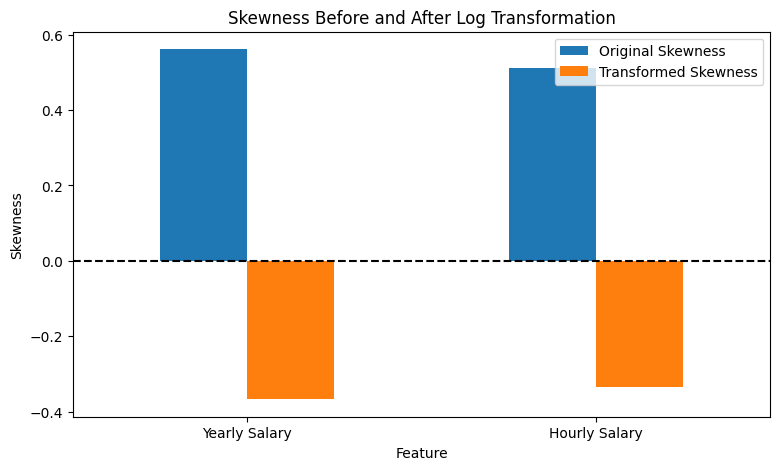

In [15]:
comparison.set_index('Feature').plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Skewness Before and After Log Transformation')
plt.ylabel('Skewness')
plt.xticks(rotation=0)
plt.axhline(y=0, color='black', linestyle='--')
plt.show()

In [16]:
# Check final dataset details

print("Final Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nNew Feature Columns:")
print(df.columns.tolist())

Final Dataset Shape: (785640, 77)

Missing Values:
4063778

Duplicate Records:
0

New Feature Columns:
['job_title_short', 'job_title', 'job_location', 'job_via', 'job_schedule_type', 'job_work_from_home', 'search_location', 'job_posted_date', 'job_no_degree_mention', 'job_health_insurance', 'job_country', 'salary_rate', 'salary_year_avg', 'salary_hour_avg', 'company_name', 'job_skills', 'job_type_skills', 'posted_year', 'posted_month', 'posted_day', 'posted_day_name', 'year_scaled', 'month_scaled', 'day_scaled', 'year_standard', 'month_standard', 'day_standard', 'schedule_Contractor', 'schedule_Contractor and Full-time', 'schedule_Contractor and Internship', 'schedule_Contractor and Part-time', 'schedule_Contractor and Per diem', 'schedule_Contractor and Temp work', 'schedule_Contractor, Temp work, and Internship', 'schedule_Full-time', 'schedule_Full-time and Contractor', 'schedule_Full-time and Internship', 'schedule_Full-time and Part-time', 'schedule_Full-time and Per diem', 'sche

In [17]:
df.to_csv(
    'Week_6_Feature_Engineered_Dataset.csv',
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!
